# HDBSCAN Euclidean - versi Kaggle / Colab

HDBSCAN adalah DBSCAN versi hierarkis: **tidak perlu `eps`**. Ia mencoba semua nilai `eps` sekaligus lalu memilih klaster yang paling stabil. Parameter pentingnya hanya dua:
- `min_samples`: seberapa "padat" sebuah titik harus dikelilingi tetangga supaya dianggap inti (di sini 2 x jumlah fitur = 40, sama dengan `MinPts` di notebook DBSCAN).
- `min_cluster_size`: ukuran klaster terkecil yang dianggap klaster. Nilai ini dipilih lewat uji beberapa nilai (sel 5).

**Pilihan data** (sel pertama): `N_SAMPLE = 10000` untuk sampel 10.000 data, atau `N_SAMPLE = None` untuk **semua data** (sekitar 208 ribu).

**Perkiraan beban**: memori kecil (di bawah 1 GB). Waktu naik kuadratik terhadap jumlah data; dari uji pada data tiruan, data penuh kira-kira belasan sampai puluhan menit per notebook (ini perkiraan kasar, belum diuji di datamu).

**Cara pakai di Kaggle**: upload CSV sebagai dataset, **Add Input**, Accelerator **None**, lalu *Save Version -> Save & Run All (Commit)*. Download `hasil_hdbscan_euclidean.zip` dari tab Output. Di Colab, data dibaca dari Drive dan hasil disimpan ke folder `outputHDBSCAN`.


In [ ]:
# import library & setting
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

_v = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
assert _v >= (1, 3), f"scikit-learn {sklearn.__version__} terlalu lama untuk HDBSCAN. Jalankan: !pip install -U scikit-learn lalu restart runtime."

# --- lokasi kerja: Kaggle atau Colab ---
from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR = "/content/drive/MyDrive/ml-semester5/HDBSCAN/outputHDBSCAN"
os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIC = 'euclidean'          # metrik untuk evaluasi (Silhouette)
METRIC_FIT = 'euclidean'      # metrik yang dipakai HDBSCAN saat klastering
N_SAMPLE = None
SWEEP_N = 10000          # uji min_cluster_size selalu pada paling banyak sekian data (hemat waktu)
SIL_SAMPLE = 10000       # ukuran sampel untuk Silhouette (titik non-noise)
PLOT_N = 30000           # jumlah titik yang digambar di grafik PCA
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def _log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


print("[INFO] Library berhasil diimpor.")
print(f"[INFO] Metrik evaluasi: {METRIC} | metrik HDBSCAN: {METRIC_FIT} | N_SAMPLE: {N_SAMPLE}")

Mounted at /content/drive
[INFO] Library berhasil diimpor.
[INFO] Metrik evaluasi: euclidean | metrik HDBSCAN: euclidean | N_SAMPLE: None


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/ml-sem5/HDBSCAN/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
df_features.describe()

In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# preprocessing + pemilihan data
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_all = scaler.fit_transform(df_features.values)
print(f"Bentuk data siap klaster: {X_all.shape}")
print(f"Cek mean 0 dan std 1: {X_all.mean():.4f} / {X_all.std():.4f}")

# Pemilihan data: N_SAMPLE = None -> semua data; angka -> sampel acak sebesar itu
if N_SAMPLE is None or N_SAMPLE >= len(X_all):
    idx_sample = np.arange(len(X_all))
else:
    rng = np.random.RandomState(RANDOM_STATE)
    idx_sample = np.sort(rng.choice(len(X_all), size=N_SAMPLE, replace=False))
X_sample = X_all[idx_sample]
y_sample = y_label.iloc[idx_sample].reset_index(drop=True)
df_sample = df_features.iloc[idx_sample].reset_index(drop=True)
print(f"[DATA] Data klastering: {X_sample.shape[0]} baris x {X_sample.shape[1]} kolom"
      f" ({'seluruh data' if len(idx_sample) == len(X_all) else 'sampel acak'})")
print(f"[DATA] Sebaran label (pembanding): {y_sample.value_counts().sort_index().to_dict()}")
df_sample.head()

Data awal: 70692 baris x 22 kolom
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek mean 0 dan std 1: 0.0000 / 1.0000
[DATA] Data klastering: 63197 baris x 15 kolom (seluruh data)
[DATA] Sebaran label (pembanding): {0.0: 29885, 1.0: 33312}


,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age
0,1.0,0.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,5.0,30.0,0.0,1.0,4.0
1,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0
2,0.0,0.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,10.0,0.0,1.0,13.0
3,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,3.0,0.0,3.0,0.0,1.0,11.0
4,0.0,0.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,8.0


In [ ]:
# uji beberapa nilai min_cluster_size (sebagai fraksi dari jumlah data)
MIN_SAMPLES = 2 * X_sample.shape[1]   # heuristik: 2 x jumlah fitur (sama dengan MinPts di DBSCAN)
print(f"[PARAM] min_samples = {MIN_SAMPLES}")


def silhouette_aman(Xm, lab):
    """Silhouette pada sampel acak (SIL_SAMPLE) dari titik non-noise; NaN kalau sampel hanya berisi 1 klaster."""
    try:
        return float(silhouette_score(Xm, lab, metric=METRIC, sample_size=min(SIL_SAMPLE, len(lab)),
                                      random_state=RANDOM_STATE))
    except ValueError:
        return np.nan


def jalankan_hdbscan(X, mcs):
    t0 = time.perf_counter()
    m = HDBSCAN(min_cluster_size=int(mcs), min_samples=MIN_SAMPLES, metric=METRIC_FIT, n_jobs=-1).fit(X)
    return m, time.perf_counter() - t0


# data untuk uji: paling banyak SWEEP_N titik (kalau data lebih besar, diambil sampel acak)
if len(X_sample) > SWEEP_N:
    idx_sw = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=SWEEP_N, replace=False))
else:
    idx_sw = np.arange(len(X_sample))
X_sw = X_sample[idx_sw]
print(f"[SWEEP] Uji pada {len(X_sw)} titik")

FRAKSI = [0.002, 0.005, 0.01, 0.02, 0.05]
rows = []
for fr in FRAKSI:
    mcs = max(2, int(round(fr * len(X_sw))))
    m, t = jalankan_hdbscan(X_sw, mcs)
    lab = m.labels_
    mk = lab != -1
    n_cl = int(lab.max() + 1) if mk.any() else 0
    largest = np.bincount(lab[mk]).max() / len(lab) * 100 if n_cl > 0 else 0.0
    sil = silhouette_aman(X_sw[mk], lab[mk]) if n_cl >= 2 else np.nan
    rows.append({
        'Fraksi dari n': fr,
        'min_cluster_size': mcs,
        'Jumlah Klaster': n_cl,
        'Noise (n)': int((~mk).sum()),
        'Noise (%)': round((~mk).mean() * 100, 2),
        'Klaster Terbesar (%)': round(largest, 2),
        'Silhouette (non-noise)': round(sil, 4) if not np.isnan(sil) else np.nan,
        'Waktu (s)': round(t, 2)
    })
    print(f"[SWEEP] fraksi={fr} (min_cluster_size={mcs}) -> {n_cl} klaster, noise {(~mk).mean() * 100:.2f}%")

sweep_df = pd.DataFrame(rows)
print("\n" + "=" * 100)
print("TABEL UJI min_cluster_size - HDBSCAN EUCLIDEAN")
print("=" * 100)
print(sweep_df.to_string(index=False))

sweep_path = os.path.join(OUTPUT_DIR, "mcs_sweep_euclidean.csv")
sweep_df.to_csv(sweep_path, index=False)
print(f"[SIMPAN] Tabel uji disimpan ke: '{sweep_path}'")

# pilih fraksi: >= 2 klaster, noise <= 30%, silhouette tertinggi (kalau tidak ada, pakai 0.005)
MCS_MANUAL = 316   # isi angka (ukuran absolut, untuk data final) kalau mau menentukan sendiri
ok = sweep_df[(sweep_df['Jumlah Klaster'] >= 2) & (sweep_df['Noise (%)'] <= 30)]
FRAKSI_FINAL = float(ok.sort_values('Silhouette (non-noise)', ascending=False).iloc[0]['Fraksi dari n']) if len(ok) > 0 else 0.005
MCS_FINAL = int(MCS_MANUAL) if MCS_MANUAL is not None else max(2, int(round(FRAKSI_FINAL * len(X_sample))))
print(f"\n[PILIH] fraksi = {FRAKSI_FINAL} -> min_cluster_size untuk data final ({len(X_sample)} titik) = {MCS_FINAL}")

[PARAM] min_samples = 30
[SWEEP] Uji pada 10000 titik
[SWEEP] fraksi=0.002 (min_cluster_size=20) -> 2 klaster, noise 2.42%
[SWEEP] fraksi=0.005 (min_cluster_size=50) -> 2 klaster, noise 2.42%
[SWEEP] fraksi=0.01 (min_cluster_size=100) -> 2 klaster, noise 2.42%
[SWEEP] fraksi=0.02 (min_cluster_size=200) -> 2 klaster, noise 2.42%
[SWEEP] fraksi=0.05 (min_cluster_size=500) -> 2 klaster, noise 2.42%

TABEL UJI min_cluster_size - HDBSCAN EUCLIDEAN
 Fraksi dari n  min_cluster_size  Jumlah Klaster  Noise (n)  Noise (%)  Klaster Terbesar (%)  Silhouette (non-noise)  Waktu (s)
         0.002                20               2        242       2.42                 92.33                   0.238       3.83
         0.005                50               2        242       2.42                 92.33                   0.238       6.23
         0.010               100               2        242       2.42                 92.33                   0.238       5.96
         0.020               200         

In [ ]:
# model final, evaluasi, profil klaster, simpan hasil
_log(f"Menjalankan HDBSCAN final pada {len(X_sample)} titik (min_cluster_size = {MCS_FINAL}, min_samples = {MIN_SAMPLES})...")
model_h, waktu_fit = jalankan_hdbscan(X_sample, MCS_FINAL)
_log(f"Selesai dalam {waktu_fit:.1f} detik.")
labels = model_h.labels_
mask = labels != -1
n_total = len(labels)
n_klaster = int(labels.max() + 1) if mask.any() else 0

if n_klaster >= 2:
    sil_score = silhouette_aman(X_sample[mask], labels[mask])
    db_score = float(davies_bouldin_score(X_sample[mask], labels[mask]))
    ch_score = float(calinski_harabasz_score(X_sample[mask], labels[mask]))
else:
    sil_score = db_score = ch_score = np.nan

sizes = np.bincount(labels[mask]) if n_klaster > 0 else np.array([0])

eval_df = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)' + (' (via Euclidean pada data ternormalisasi)' if METRIC != METRIC_FIT else ''),
    'MinPts (min_samples)': MIN_SAMPLES,
    'min_cluster_size': MCS_FINAL,
    'Jumlah Data Dipakai': n_total,
    'Jumlah Fitur': X_sample.shape[1],
    'Jumlah Klaster': n_klaster,
    'Klaster >=1% data': int(np.sum(sizes >= 0.01 * n_total)),
    'Noise (n)': int((~mask).sum()),
    'Noise (%)': round((~mask).sum() / n_total * 100, 2),
    'Silhouette Score (non-noise) (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (non-noise) (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (non-noise) (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(waktu_fit, 5),
    'Ukuran Sampel Silhouette': int(min(SIL_SAMPLE, int(mask.sum())))
}])

print("\n" + "=" * 80)
print("TABEL EVALUASI HDBSCAN EUCLIDEAN")
print("=" * 80)
print(eval_df.T.to_string(header=False))
print("=" * 80)

df_result = df_sample.copy()
df_result['Cluster_HDBSCAN'] = labels
df_result[LABEL] = y_sample.values

profil = df_result.groupby('Cluster_HDBSCAN').mean().round(3)
profil.insert(0, 'Jumlah Data', df_result.groupby('Cluster_HDBSCAN').size())
profil['% Diabetes'] = df_result.groupby('Cluster_HDBSCAN')[LABEL].apply(lambda s: (s == 1).mean() * 100).round(2)

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_hdbscan_euclidean.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    profil.to_excel(writer, sheet_name='Profil_Klaster')
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster_hdbscan_euclidean.csv")
df_result.to_csv(csv_path, index=False)
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")

[07:12:08] Menjalankan HDBSCAN final pada 63197 titik (min_cluster_size = 316, min_samples = 30)...
[07:14:39] Selesai dalam 151.1 detik.

TABEL EVALUASI HDBSCAN EUCLIDEAN
Distance Metric                          Euclidean Distance (L2)
MinPts (min_samples)                                          30
min_cluster_size                                             316
Jumlah Data Dipakai                                        63197
Jumlah Fitur                                                  15
Jumlah Klaster                                                45
Klaster >=1% data                                             25
Noise (n)                                                  10932
Noise (%)                                                   17.3
Silhouette Score (non-noise) (↑)                          0.0828
Davies–Bouldin Index (non-noise) (↓)                      1.5936
Calinski–Harabasz Index (non-noise) (↑)                  1312.88
Execution Time (s) (↓)                          

In [ ]:
# profil tiap klaster (label -1 = noise)
profil

,Jumlah Data,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,% Diabetes
Cluster_HDBSCAN,,,,,,,,,,,,,,,,,,
-1,10932,0.549,0.484,33.470,0.532,0.008,0.130,0.538,0.527,0.723,3.571,12.898,15.937,0.569,0.416,8.187,0.596,59.60
0,4301,0.816,0.725,30.213,0.602,1.000,0.458,0.562,0.598,0.715,3.662,6.289,12.157,0.579,0.465,9.992,0.747,74.66
1,6842,0.836,0.776,30.422,0.637,0.000,1.000,0.634,0.604,0.804,3.434,2.956,8.557,0.434,0.612,10.284,0.737,73.71
2,8992,0.578,0.527,29.851,0.453,0.000,0.000,0.625,0.375,0.000,2.759,1.842,3.232,0.183,0.503,8.418,0.509,50.87
3,1085,0.000,0.335,28.227,0.500,0.000,0.000,0.000,0.000,1.000,2.340,1.185,1.180,0.000,0.496,7.140,0.274,27.37
4,1247,1.000,0.626,31.439,0.502,0.000,0.000,0.000,0.000,1.000,2.868,0.993,1.544,0.000,0.496,9.048,0.610,61.03
5,588,0.000,0.321,27.920,0.483,0.000,0.000,0.000,1.000,1.000,2.369,0.648,0.878,0.000,1.000,7.699,0.313,31.29
6,880,0.000,0.303,28.169,0.353,0.000,0.000,0.000,1.000,1.000,2.319,1.166,1.219,0.000,0.000,7.610,0.217,21.70
7,666,1.000,0.604,30.830,0.527,0.000,0.000,0.000,1.000,1.000,2.724,0.764,1.219,0.000,1.000,9.093,0.610,60.96


[SIMPAN] Grafik pemetaan klaster disimpan ke: '/content/drive/MyDrive/ml-sem5/HDBSCAN/outputHDBSCAN/cluster_hdbscan_euclidean.png'


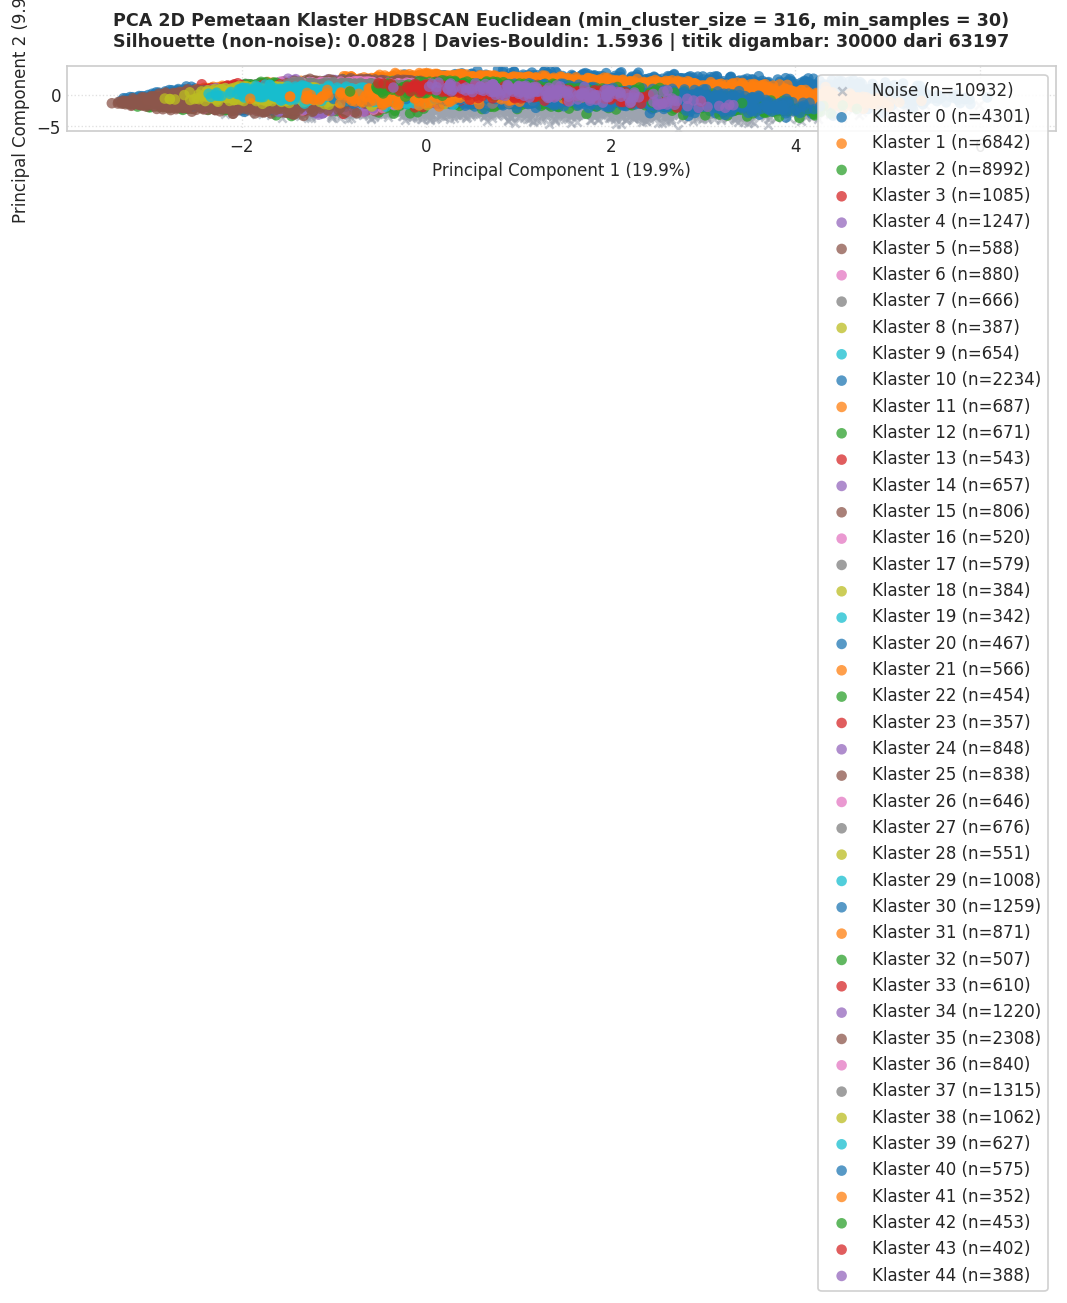

In [ ]:
# visualisasi PCA 2D pemetaan klaster
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sample)

# gambar hanya PLOT_N titik acak supaya ringan; hitungan n di legenda tetap dari SEMUA data
if len(X_sample) > PLOT_N:
    idx_plot = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=PLOT_N, replace=False))
else:
    idx_plot = np.arange(len(X_sample))
Xp, lp = X_pca[idx_plot], labels[idx_plot]

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab10", max(n_klaster, 1))

m_noise = lp == -1
plt.scatter(Xp[m_noise, 0], Xp[m_noise, 1], c='#9CA3AF', marker='x', s=25, alpha=0.6,
            label=f'Noise (n={(labels == -1).sum()})')
for k in range(n_klaster):
    mk = lp == k
    plt.scatter(Xp[mk, 0], Xp[mk, 1], color=palette[k % len(palette)], s=40, alpha=0.75, edgecolors='none',
                label=f'Klaster {k} (n={(labels == k).sum()})')

plt.title(f'PCA 2D Pemetaan Klaster HDBSCAN Euclidean (min_cluster_size = {MCS_FINAL}, min_samples = {MIN_SAMPLES})\n'
          f'Silhouette (non-noise): {sil_score:.4f} | Davies-Bouldin: {db_score:.4f} | titik digambar: {len(idx_plot)} dari {len(X_sample)}',
          fontsize=10.5, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_hdbscan_euclidean.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()


In [ ]:
# fitur paling berpengaruh di PC1 & PC2
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])
print("Fitur paling berpengaruh di PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))
print("\nFitur paling berpengaruh di PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))

Fitur paling berpengaruh di PC1:
GenHlth                 0.441
DiffWalk                0.408
PhysHlth                0.398
HighBP                  0.295
HeartDiseaseorAttack    0.264
PhysActivity            0.241
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age                     0.524
MentHlth                0.417
HighBP                  0.327
HeartDiseaseorAttack    0.308
HighChol                0.286
PhysHlth                0.256
Name: PC2, dtype: float64


In [ ]:
# klaster vs label diabetes (pembanding)
label_vs = pd.crosstab(df_result['Cluster_HDBSCAN'], df_result[LABEL])
label_vs.columns = ['Tidak Diabetes (0)' if c == 0 else 'Diabetes (1)' for c in label_vs.columns]
label_vs['Total'] = label_vs.sum(axis=1)
if 'Diabetes (1)' in label_vs.columns:
    label_vs['Diabetes (%)'] = (label_vs['Diabetes (1)'] / label_vs['Total'] * 100).round(2)
print(f"Proporsi diabetes seluruh sampel = {(y_sample == 1).mean() * 100:.2f}%")
print(label_vs.to_string())

if n_klaster >= 2:
    ari = adjusted_rand_score(y_sample.values[mask], labels[mask])
    print(f"\nARI klaster vs label (non-noise): {ari:.4f}")
diab_noise = int(((labels == -1) & (y_sample.values == 1)).sum())
print(f"Diabetes di noise: {diab_noise} dari {int((y_sample == 1).sum())}")

Proporsi diabetes seluruh sampel = 52.71%
                 Tidak Diabetes (0)  Diabetes (1)  Total  Diabetes (%)
Cluster_HDBSCAN                                                       
-1                             4417          6515  10932         59.60
 0                             1090          3211   4301         74.66
 1                             1799          5043   6842         73.71
 2                             4418          4574   8992         50.87
 3                              788           297   1085         27.37
 4                              486           761   1247         61.03
 5                              404           184    588         31.29
 6                              689           191    880         21.70
 7                              260           406    666         60.96
 8                              195           192    387         49.61
 9                              207           447    654         68.35
 10                             529

In [ ]:
# ===== ARI & NMI vs label Diabetes_binary =====
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ALGO_NAME, METRIK_NAME = 'HDBSCAN', 'Euclidean'

y_true = y_sample.values if 'y_sample' in globals() else y_label.values
lab = np.asarray(labels)
mk = lab != -1                                    # K-Means: semua True (tidak ada noise)

hasil_ext = pd.DataFrame([{
    'Algoritma': ALGO_NAME, 'Metrik': METRIK_NAME,
    'ARI (non-noise)':   round(adjusted_rand_score(y_true[mk], lab[mk]), 4),
    'NMI (non-noise)':   round(normalized_mutual_info_score(y_true[mk], lab[mk]), 4),
    'ARI (semua titik)': round(adjusted_rand_score(y_true, lab), 4),   # noise = 1 label (-1)
    'NMI (semua titik)': round(normalized_mutual_info_score(y_true, lab), 4),
}])
print(hasil_ext.to_string(index=False))

out = globals().get('OUTPUT_DIR', '.')
hasil_ext.to_excel(os.path.join(out, f'ari_nmi_{ALGO_NAME.lower()}_{METRIK_NAME.lower()}.xlsx'), index=False)

Algoritma    Metrik  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)
  HDBSCAN Euclidean           0.0163            0.043              0.013             0.0376
